# Chromatic companion search: a Wolf-Rayet star and an OB companion

A Wolf-Rayet (WR) star has strong emission lines, and its OB companion has none. Across a line the WR star brightens while the companion stays put, so the companion-to-primary flux ratio drops through the line and the differential phase moves with it. This is the information that a grey (wavelength-independent) flux ratio throws away, and it reaches separations far below the resolution of the baselines, where V² and closure phases are nearly blind.

This notebook shows the pieces for a chromatic search in virgil: a primary with a continuum plus a Gaussian emission line, a companion whose spectrum is a fixed shape times one free amplitude (`Scaled`), simulated GRAVITY-like data with V², closure phases, differential phases and a flux spectrum, and the standard grid, limit and detection tools run on `comp.flux.ratio`. You should come away knowing how to set up the scene and which flux key to search over.

We begin with the scene and the data. The primary is a point source with a unit continuum and a Brγ emission line three times as bright as the continuum at its peak. The companion has the continuum of an OB star, a power law of index zero over this narrow band, wrapped in `Scaled`, so that its single free parameter is the amplitude `comp.flux.ratio`, the flux ratio at the reference wavelength. The data have four telescopes, two snapshots and nine channels across the line, and we simulate noise on them with a fixed seed. The printed numbers are the flux ratio in the continuum and at the line centre.

In [1]:
import warnings

warnings.filterwarnings("ignore")  # coarse demo grids trip the peak-resolution warnings

import jax
import numpy as onp
import matplotlib.pyplot as plt

from virgil import GaussianLine, OIData, PointSource, PowerLaw, Scaled, Sum, System
from virgil.coverage import vlti_oidata
from virgil.detection import detection_statistics
from virgil.grid_fit import linear_flux_grid
from virgil.limits import injection_limits
from virgil.plotting import plot_grid_map, set_style

set_style()
BRG, FWHM = 2.1661e-6, 1.5e-9
waves = onp.linspace(BRG - 3e-9, BRG + 3e-9, 9)
continuum = [(waves[0] - 1e-10, waves[1] + 1e-10), (waves[-2] - 1e-10, waves[-1] + 1e-10)]
line = [(waves[3] - 1e-10, waves[5] + 1e-10)]

def wr_system(ratio, dra=8.0, ddec=-5.0):
    star = PointSource(flux=Sum(continuum=PowerLaw(1.0, wavel0=BRG), brg=GaussianLine(3.0, BRG, FWHM)))
    comp = PointSource(dra=dra, ddec=ddec, flux=Scaled(PowerLaw(1.0, wavel0=BRG), ratio))
    return System(star=star, comp=comp)

def template(blocks=("v2", "t3", "visphi", "flux"), sigma_phi=0.01):
    """GRAVITY AT-like snapshots with zero data, as an OIData dictionary."""
    base = vlti_oidata(hour_angles_h=(-1.0, 1.0), wavelengths_m=waves, sigma_v2=0.01, sigma_cp_deg=0.5)
    n = base.u.size
    rec = dict(u=onp.asarray(base.u), v=onp.asarray(base.v), wavel=onp.asarray(base.wavel),
               frame=onp.asarray(base.frame), stations=onp.asarray(base.stations),
               vis=onp.ones(n), d_vis=onp.full(n, 0.01), phi=onp.zeros(base.phi.size),
               d_phi=onp.full(base.phi.size, onp.radians(0.5)), i_cps1=onp.asarray(base.i_cps1),
               i_cps2=onp.asarray(base.i_cps2), i_cps3=onp.asarray(base.i_cps3))
    if "v2" not in blocks:
        rec["vis"] = onp.full(n, onp.nan)
    if "t3" not in blocks:
        rec.update(i_cps1=None, i_cps2=None, i_cps3=None, phi=None, d_phi=None, cp_flag=False)
    if "visphi" in blocks:
        rec["visphi"] = dict(sample=onp.arange(n), value=onp.zeros(n), error=onp.full(n, sigma_phi))
    if "flux" in blocks:
        rows = onp.repeat(onp.arange(n // waves.size), waves.size)
        rec["flux"] = dict(wavel=onp.asarray(base.wavel), value=onp.ones(n), error=onp.full(n, 0.05), row=rows)
    return rec

def observe(truth, blocks=("v2", "t3", "visphi", "flux"), sigma_phi=0.01, seed=1):
    data = OIData(template(blocks, sigma_phi))
    if "flux" in blocks:
        data = data.with_flux_scale(scale=(1.0, 0.5))
    if "visphi" in blocks:
        data = data.with_continuum(continuum, lines=line)
    return data.with_model(truth, key=jax.random.PRNGKey(seed))

truth = wr_system(0.08)
data = observe(truth)
total = truth.total_spectrum(waves)
print(f"flux ratio in the continuum: {0.08:.3f}")
print(f"flux ratio at the line centre: {0.08 / float(total[4]):.3f}")

flux ratio in the continuum: 0.080
flux ratio at the line centre: 0.020


The figure shows what the model predicts per channel: the total flux of the system and the companion's fraction of it. The companion's flux is constant, but the primary's line lifts the total, so the fraction falls from about 8 per cent in the continuum to about 2 per cent at the line centre. That change, not its mean, is what the differential phase measures.

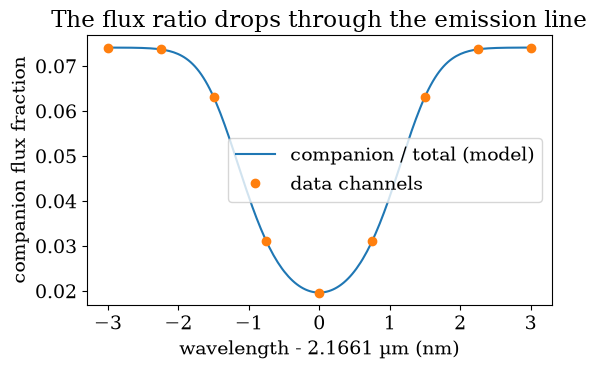

In [2]:
fig, ax = plt.subplots(figsize=(6, 3.5))
fine = onp.linspace(waves[0], waves[-1], 200)
fraction = 0.08 / truth.total_spectrum(fine)
ax.plot((fine - BRG) * 1e9, fraction, label="companion / total (model)")
ax.plot((waves - BRG) * 1e9, 0.08 / total, "o", label="data channels")
ax.set_xlabel("wavelength - 2.1661 µm (nm)")
ax.set_ylabel("companion flux fraction")
ax.set_title("The flux ratio drops through the emission line")
ax.legend()
plt.show()

Now we search for the companion. The quickest tool is `linear_flux_grid`, which solves for the companion flux in closed form at every position of the grid. We hand it a template in which the companion has `Scaled(...)` with a starting ratio, and name the flux axis `comp.flux.ratio`; its values are ignored, but the key says which parameter is the flux. All four kinds of data enter the likelihood together. The map shows the signal-to-noise of the best-fitting flux at each position; the cross marks the injected position, and the printed numbers compare the recovered flux with the injected 0.08. There is no model fitted to data here, only a linearised search, so we leave out the data-model correlation plot, and use the detection statistics below to quantify the result.

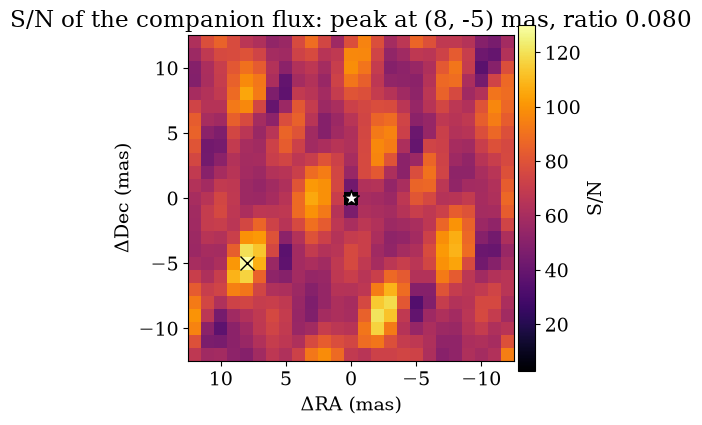

In [3]:
axis = onp.arange(-12.0, 12.1, 1.0)
grid = {"comp.dra": axis, "comp.ddec": axis, "comp.flux.ratio": onp.array([0.0])}
search = linear_flux_grid(wr_system(0.05), data, grid, n_iter=3)
snr = onp.asarray(search.snr)
i, j = onp.unravel_index(onp.nanargmax(snr), snr.shape)
fig, ax = plt.subplots(figsize=(5, 4.5))
plot_grid_map(snr, grid={"dra": axis, "ddec": axis}, kind="snr", ax=ax)
ax.plot(8.0, -5.0, "kx", ms=10)
ax.set_title(f"S/N of the companion flux: peak at ({axis[i]:.0f}, {axis[j]:.0f}) mas, ratio {float(search.flux[i, j]):.3f}")
plt.show()

A search is only useful if we also know what it could have seen. `injection_limits` adds a companion to the data at each position, with its chromatic signal in every observable, and reports the flux ratio at which the null model would be rejected at 3σ. We evaluate it at a handful of separations along one direction. The data themselves contain the companion at (8, −5) mas, so we ask it of the empty positions only: the limits are on `comp.flux.ratio`, in the continuum, and the loop has a progress bar because each position needs a bracketing search.

In [4]:
seps = onp.array([-10.0, -6.0, 0.0, 4.0])
limits = []
for dra in seps:
    point = {"comp.dra": onp.array([dra]), "comp.ddec": onp.array([-5.0]), "comp.flux.ratio": onp.array([0.01])}
    limits.append(float(injection_limits(wr_system(0.05), data, point, 3.0)[0, 0]))
for dra, limit in zip(seps, limits):
    print(f"dra = {dra:6.1f} mas: 3-sigma limit on the continuum flux ratio = {limit:.4f}")

dra =  -10.0 mas: 3-sigma limit on the continuum flux ratio = 0.0574
dra =   -6.0 mas: 3-sigma limit on the continuum flux ratio = 0.0118
dra =    0.0 mas: 3-sigma limit on the continuum flux ratio = 0.0115
dra =    4.0 mas: 3-sigma limit on the continuum flux ratio = 0.0154


Finally the sub-resolution case, which is why the chromatic model matters. We move the companion to 0.1 mas, a fiftieth of the 4 mas resolution of a 130 m baseline, and ask two questions of data simulated with the same random seed (the differential-phase errors, 0.005 rad, are smaller than the closure-phase errors, 0.0087 rad, and there are more phases per sample, so part of the gap below is the setup rather than the line). A search with the chromatic model on the differential phases alone sees the shifting photocentre; a search with a grey flux ratio on the V² and closure phases sees almost nothing, since those change only at second order or higher in the separation. The statistic is `delta_chi2`, the improvement in χ² from the best companion over the grid, which for a null result is of order 1 to 10 because it is the maximum over positions and fluxes.

In [5]:
sep = 0.1
sub = wr_system(0.2, dra=sep, ddec=0.0)
differential = observe(sub, ("visphi",), sigma_phi=0.005, seed=2)
grey = observe(sub, ("v2", "t3"), seed=2)
axes = {"comp.dra": onp.array([-sep, 0.0, sep]), "comp.ddec": onp.zeros(1)}
ratios = onp.geomspace(0.05, 0.5, 8)
chromatic = detection_statistics(wr_system(0.1), differential, {**axes, "comp.flux.ratio": ratios})
constant = detection_statistics(System(star=PointSource(flux=Sum(continuum=PowerLaw(1.0, wavel0=BRG), brg=GaussianLine(3.0, BRG, FWHM))), comp=PointSource(flux=0.1)), grey, {**axes, "comp.flux": ratios})
print(f"differential phase, chromatic model: delta chi2 = {float(chromatic['delta_chi2']):.1f}")
print(f"V2 and closure phase, grey ratio:    delta chi2 = {float(constant['delta_chi2']):.1f}")

differential phase, chromatic model: delta chi2 = 65.7
V2 and closure phase, grey ratio:    delta chi2 = 1.3


The line turns a companion that is invisible to V² and closure phases into a clear detection in the differential phase, with the same channels and seed, helped by its smaller phase errors. In practice you would run the full recipe of this page on each star: a `linear_flux_grid` map to find candidates, `injection_limits` for what the data exclude, and `detection_statistics` with simulated null draws (see the detection-ROC tutorial) for a false-alarm probability. Throughout, `comp.flux.ratio` is the flux axis, and any fixed spectral shape, not only a power law, can be the companion's by wrapping it in `Scaled`.